# DL — GRU (Gated Recurrent Unit): OHLCV vs OHLCV + Indicators
### TCS Stock Price Prediction | Deep Learning — GRU (Gated Recurrent Unit)
**Target:** Next-day Return → back-converted to Price | **Seeds:** 42 | **Test rows:** same as ML notebooks (~1067)


## Why GRU for Stock Price Prediction?
> **GRU (Gated Recurrent Unit)** is a simplified LSTM with two gates (reset, update).  
> It trains faster than LSTM with comparable accuracy on many time-series tasks.  
> Preferred when training speed matters and sequences are moderately long.


In [1]:
# Dependencies already installed in environment
# !pip install mplfinance scikit-learn -q
print('Dependencies ready!')


Dependencies ready!


---
## Step 0: Reproducibility — Set All Random Seeds to 42
Setting `numpy`, `python random`, and `tensorflow` seeds to **42** for fully reproducible results.


In [2]:
import os, random
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['PYTHONHASHSEED'] = '42'
random.seed(42)

import numpy as np
np.random.seed(42)

import tensorflow as tf
tf.random.set_seed(42)

# Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print('All imports done! TensorFlow version:', tf.__version__)
print('All random seeds set to 42.')


All imports done! TensorFlow version: 2.21.0
All random seeds set to 42.


---
## Step 1: Load TCS Dataset
Reading `TCS.csv` (skiprows=[1,2]), parsing date index, keeping OHLCV columns, dropping NaN rows.


In [3]:
df = pd.read_csv('TCS.csv', skiprows=[1, 2])
if 'Price' in df.columns:
    df.rename(columns={'Price': 'Date'}, inplace=True)
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)
df = df.sort_index()[['Open', 'High', 'Low', 'Close', 'Volume']]

for col in ['Open', 'High', 'Low', 'Close', 'Volume']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.dropna(inplace=True)
print(f'Shape: {df.shape}')
print(f'Date range: {df.index.min().date()} to {df.index.max().date()}')
df.head()


Shape: (5363, 5)
Date range: 2005-01-03 to 2026-09-23


,Open,High,Low,Close,Volume
Date,,,,,
2005-01-03,106.283498,107.973897,106.283498,107.700127,4734168
2005-01-04,107.440734,107.759077,106.100513,106.745155,4979104
2005-01-05,106.660803,106.660803,101.893625,105.451103,9604320
2005-01-06,105.053169,107.122398,102.864561,105.089775,8006888
2005-01-07,105.848984,107.042770,104.468971,106.641655,7623136


In [4]:
print('Missing values per column:')
print(df.isnull().sum())
print(f'Volume == 0: {(df["Volume"] == 0).sum()} rows')


Missing values per column:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Volume == 0: 9 rows


In [5]:
print('Dataset Statistics:')
display(df.describe().round(2))


Dataset Statistics:


,Open,High,Low,Close,Volume
count,5363.00,5363.00,5363.00,5363.00,5363.00
mean,1337.33,1350.53,1323.25,1336.56,3350520.35
std,1182.66,1192.74,1172.07,1182.00,2819411.07
min,75.39,78.16,69.06,75.09,0.00
25%,272.82,276.23,269.14,272.56,1853218.00
50%,954.48,961.94,946.02,953.56,2650784.00
75%,2371.06,2401.41,2337.23,2363.71,3987019.00
max,4228.90,4243.92,4169.75,4208.34,88067154.00


---
## Step 2: Exploratory Data Analysis (EDA)
**Graphs:** Close price history | Candlestick (last 200 days) | Volume bar | OHLC line chart.


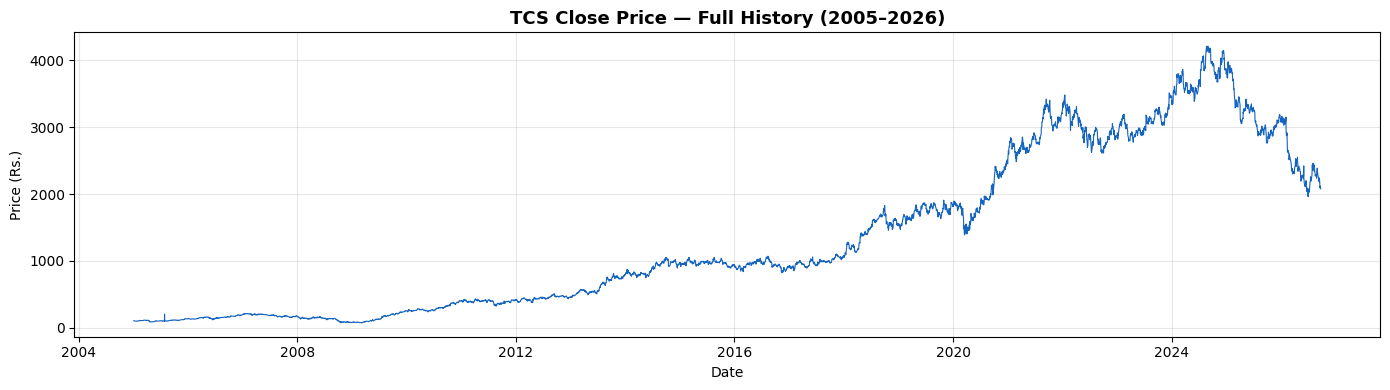

In [6]:
# Full history Close price
plt.figure(figsize=(14, 4))
plt.plot(df['Close'], color='#1565C0', lw=0.8)
plt.title('TCS Close Price — Full History (2005–2026)', fontsize=13, fontweight='bold')
plt.xlabel('Date'); plt.ylabel('Price (Rs.)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


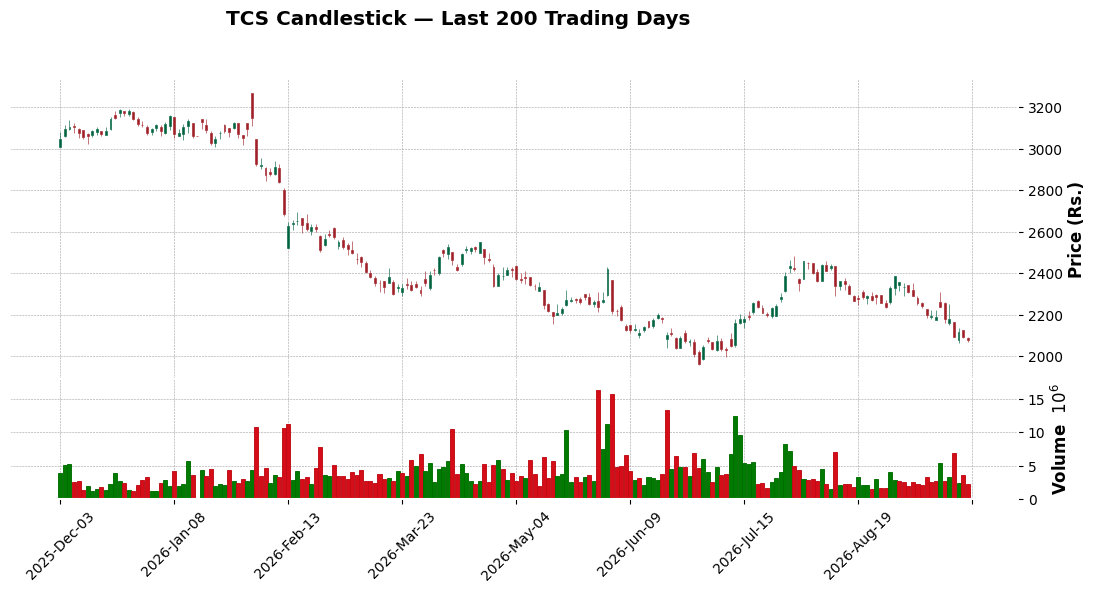

In [7]:
# Candlestick — Last 200 trading days
candle_df = df.tail(200).copy()
candle_df.index = pd.DatetimeIndex(candle_df.index)
mpf.plot(candle_df, type='candle', style='charles',
         title='TCS Candlestick — Last 200 Trading Days',
         ylabel='Price (Rs.)', volume=True,
         figsize=(14, 6), warn_too_much_data=400)


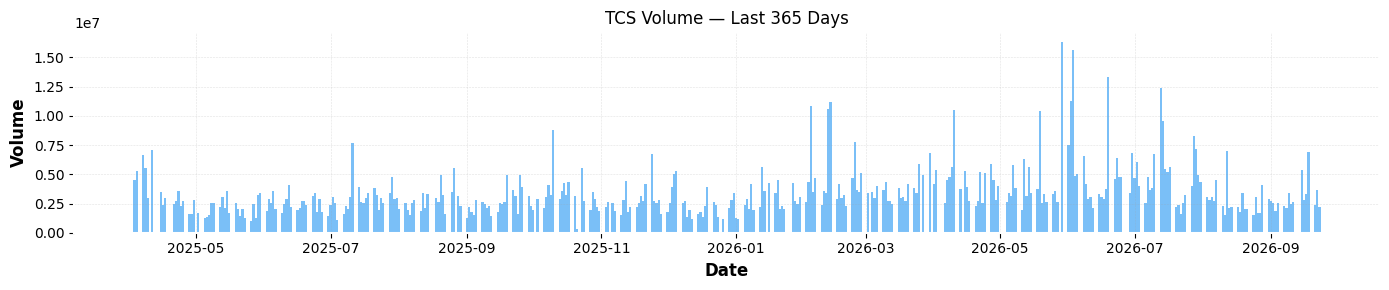

In [8]:
# Volume — Last 365 days
vol_df = df.tail(365)
plt.figure(figsize=(14, 3))
plt.bar(vol_df.index, vol_df['Volume'], color='#42A5F5', alpha=0.7, width=1)
plt.title('TCS Volume — Last 365 Days')
plt.xlabel('Date'); plt.ylabel('Volume')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


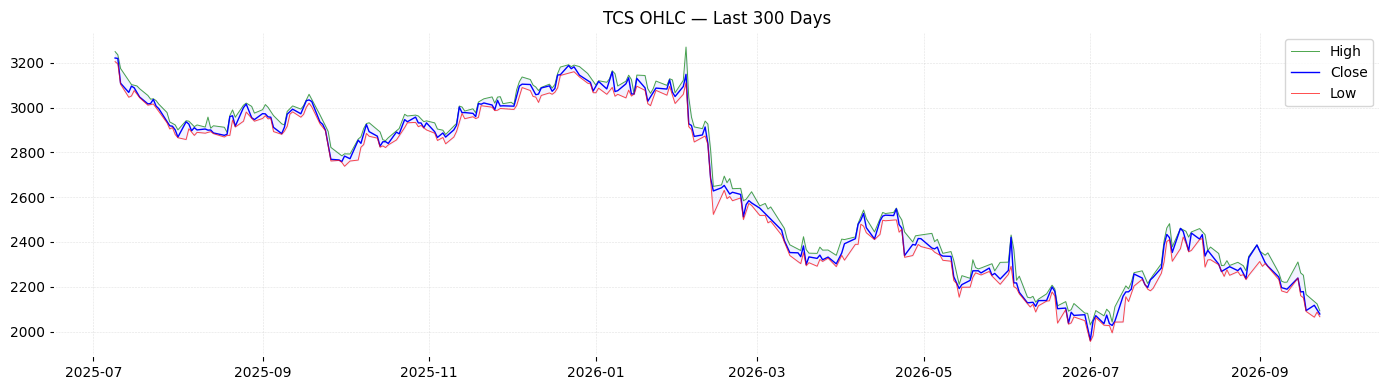

In [9]:
# OHLC line chart — last 300 days
ohlc_df = df.tail(300)
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(ohlc_df.index, ohlc_df['High'],  label='High',  color='green', lw=0.7, alpha=0.7)
ax.plot(ohlc_df.index, ohlc_df['Close'], label='Close', color='blue',  lw=1.0)
ax.plot(ohlc_df.index, ohlc_df['Low'],   label='Low',   color='red',   lw=0.7, alpha=0.7)
ax.fill_between(ohlc_df.index, ohlc_df['Low'], ohlc_df['High'], alpha=0.05, color='blue')
ax.set_title('TCS OHLC — Last 300 Days'); ax.legend()
ax.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


---
## Step 3: Define Return Target & Train-Test Split (80/20)
**Target:** `y_ret = Next_Close / Close - 1` (next-day simple return, NOT raw price)  
**Split:** ~4296 train rows | ~1067 test rows — same as ML notebooks.  
First test sequence allowed to look back into train end (past data, not leakage).


In [10]:
LOOK_BACK = 60   # 60-day sequence window (standard in literature)
SET_A     = ['Open', 'High', 'Low', 'Close', 'Volume']

# ── Build return-based target ──────────────────────────────────────
df_work = df.copy()
df_work['Next_Close']  = df_work['Close'].shift(-1)
df_work['Target_Ret']  = df_work['Next_Close'] / df_work['Close'] - 1   # next-day return

# Store close/next BEFORE slicing to avoid duplicate column issue
close_series = df_work['Close'].copy()
next_series  = df_work['Next_Close'].copy()
ret_series   = df_work['Target_Ret'].copy()

# Align everything on the same index (drop rows where target is NaN)
valid_idx = ret_series.dropna().index
df_A = df_work.loc[valid_idx, SET_A].copy()
y_ret_A    = ret_series.loc[valid_idx].values       # returns (target)
close_A    = close_series.loc[valid_idx].values     # today's close
next_A     = next_series.loc[valid_idx].values      # actual next-day close

X_A = df_A[SET_A].values

n_tr = int(len(X_A) * 0.8)
X_A_train, X_A_test       = X_A[:n_tr],     X_A[n_tr:]
y_A_train, y_A_test       = y_ret_A[:n_tr], y_ret_A[n_tr:]
close_A_train, close_A_test = close_A[:n_tr], close_A[n_tr:]
next_A_train,  next_A_test  = next_A[:n_tr],  next_A[n_tr:]

print(f'Total rows (after dropna): {len(X_A)}')
print(f'Train: {X_A_train.shape}  |  Test: {X_A_test.shape}  (same ~1067 test rows as ML notebooks)')
print(f'y_A_train stats -> mean={y_A_train.mean():.4f}  std={y_A_train.std():.4f}')


Total rows (after dropna): 5362
Train: (4289, 5)  |  Test: (1073, 5)  (same ~1067 test rows as ML notebooks)
y_A_train stats -> mean=0.0011  std=0.0258


### Data Inspection — Set A Stats


In [11]:
print('Set A — OHLCV (5 features), modelling rows only')
print('='*65)
display(pd.DataFrame(X_A, columns=SET_A).describe().round(2))


Set A — OHLCV (5 features), modelling rows only


,Open,High,Low,Close,Volume
count,5362.00,5362.00,5362.00,5362.00,5362.00
mean,1337.19,1350.39,1323.11,1336.43,3350729.62
std,1182.73,1192.81,1172.13,1182.07,2819632.36
min,75.39,78.16,69.06,75.09,0.00
25%,272.74,276.21,269.09,272.51,1853135.00
50%,954.43,961.91,945.98,953.46,2650817.00
75%,2371.18,2401.45,2338.16,2364.35,3987605.50
max,4228.90,4243.92,4169.75,4208.34,88067154.00


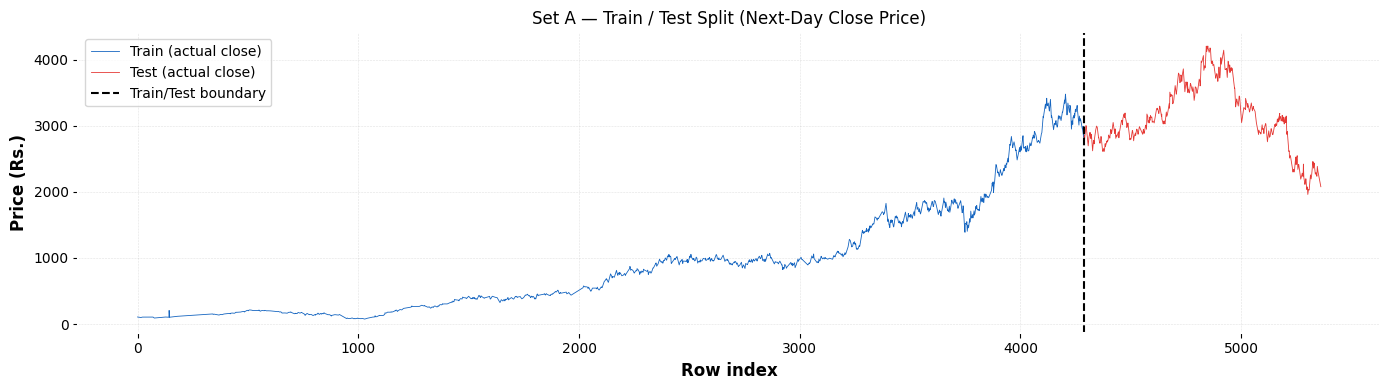

In [12]:
# Train vs Test split visualization (price)
n_te = len(next_A_test)
plt.figure(figsize=(14, 4))
plt.plot(range(n_tr), next_A_train, color='#1565C0', lw=0.6, label='Train (actual close)')
plt.plot(range(n_tr, n_tr + n_te), next_A_test, color='#E53935', lw=0.6, label='Test (actual close)')
plt.axvline(n_tr, color='black', lw=1.5, linestyle='--', label='Train/Test boundary')
plt.title('Set A — Train / Test Split (Next-Day Close Price)')
plt.xlabel('Row index'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


---
---
# Part A: GRU (Gated Recurrent Unit) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


---
---
# Part A: GRU (Gated Recurrent Unit) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [13]:
# StandardScaler for features (fit on train only)
scaler_XA = StandardScaler()
X_A_tr_sc = scaler_XA.fit_transform(X_A_train)
X_A_te_sc = scaler_XA.transform(X_A_test)

# StandardScaler for return target (fit on train only)
scaler_yA = StandardScaler()
y_A_tr_sc = scaler_yA.fit_transform(y_A_train.reshape(-1, 1)).flatten()
y_A_te_sc = scaler_yA.transform(y_A_test.reshape(-1, 1)).flatten()

print('Feature scaler — train mean/std:', scaler_XA.mean_.round(2), '/', scaler_XA.scale_.round(2))
print('Target scaler  — train mean/std:', round(scaler_yA.mean_[0],6), '/', round(scaler_yA.scale_[0],6))


Feature scaler — train mean/std: [8.90650000e+02 9.00290000e+02 8.80270000e+02 8.90140000e+02
 3.53575654e+06] / [8.31000000e+02 8.38710000e+02 8.22440000e+02 8.30360000e+02
 3.01040163e+06]
Target scaler  — train mean/std: 0.00107 / 0.025775


---
---
# Part A: GRU (Gated Recurrent Unit) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [14]:
def create_seq(X_sc, y_sc, lb=60):
    """
    Create (X, y) sequences of length lb.
    For test set, the first lb rows of X_sc may overlap with train end
    — that is intentional and allowed (past data only).
    """
    Xs, ys = [], []
    for i in range(lb, len(X_sc)):
        Xs.append(X_sc[i-lb:i])
        ys.append(y_sc[i])
    return np.array(Xs, dtype='float32'), np.array(ys, dtype='float32')

# For test sequences we concatenate last LOOK_BACK train rows with test rows
X_A_joined = np.vstack([X_A_tr_sc[-LOOK_BACK:], X_A_te_sc])
y_A_joined = np.concatenate([y_A_tr_sc[-LOOK_BACK:], y_A_te_sc])

X_A_tr_seq, y_A_tr_seq = create_seq(X_A_tr_sc, y_A_tr_sc)
X_A_te_seq, y_A_te_seq = create_seq(X_A_joined, y_A_joined)

print(f'Train sequences: {X_A_tr_seq.shape}')
print(f'Test  sequences: {X_A_te_seq.shape}  (first window looks back into train end)')


Train sequences: (4229, 60, 5)
Test  sequences: (1073, 60, 5)  (first window looks back into train end)


---
---
# Part A: GRU (Gated Recurrent Unit) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [15]:
def build_gru(timesteps, n_feat):
    m = Sequential([
        GRU(64, return_sequences=True, input_shape=(timesteps, n_feat)),
        Dropout(0.2),
        GRU(32),
        Dropout(0.2),
        Dense(16, activation='relu'),
        Dense(1)
    ])
    m.compile(optimizer=Adam(0.001), loss='mse')
    return m

gru_A = build_gru(LOOK_BACK, len(SET_A))
gru_A.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 60, 64)         │        13,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,585 (92.13 KB)

 Trainable params: 23,585 (92.13 KB)

 Non-trainable params: 0 (0.00 B)

---
---
# Part A: GRU (Gated Recurrent Unit) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [16]:
cb = [
    EarlyStopping(patience=15, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(factor=0.5, patience=7, verbose=1)
]
history_A = gru_A.fit(
    X_A_tr_seq, y_A_tr_seq,
    epochs=100, batch_size=32,
    validation_split=0.1,
    callbacks=cb, verbose=1
)


Epoch 1/100


  1/119 ━━━━━━━━━━━━━━━━━━━━ 8:16 4s/step - loss: 0.6378

  3/119 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - loss: 0.8386

  5/119 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - loss: 0.7542

  7/119 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - loss: 0.6831

...

117/119 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 1.0982

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 1.0859

119/119 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - loss: 1.0859 - val_loss: 0.3241 - learning_rate: 2.5000e-04


Epoch 19: early stopping


Restoring model weights from the end of the best epoch: 4.


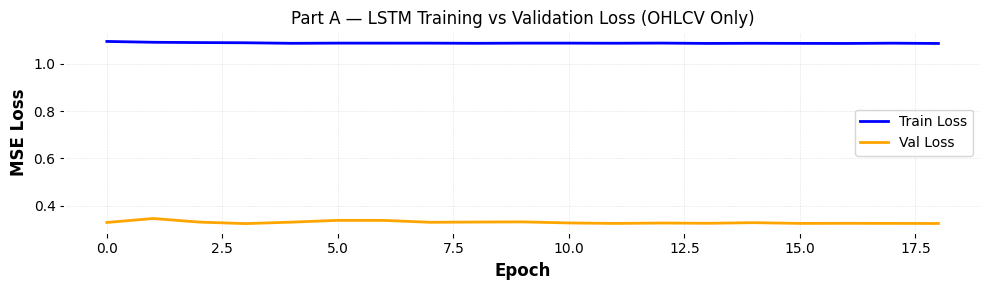

In [17]:
plt.figure(figsize=(10, 3))
plt.plot(history_A.history['loss'],     label='Train Loss', color='blue')
plt.plot(history_A.history['val_loss'], label='Val Loss',   color='orange')
plt.title('Part A — LSTM Training vs Validation Loss (OHLCV Only)')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


### Train vs Validation Loss Curve — Interpretation
- **Converging curves (train ≈ val):** Model generalises well — **Good Fit**.
- **Large gap (train << val):** Validation loss much higher — **Overfitting** (model memorised training data).
- **Both curves high / flat:** Model cannot capture patterns — **Underfitting**.
- Early stopping ensures training halts once val loss stops improving, preventing runaway overfitting.
